# Transformer-to-VLA

## Multimodal Transformer

### Cross-Attention 与联合 Self-Attention

---

**目标**

比较文本从视觉 memory 读取信息与图文共同参与 Self-Attention 的计算区别。

**核心概念**

- Query / Key / Value Sources
- From-Scratch Multi-Head Attention
- Key Competition
- Residual Fusion
- Per-Head Visualization

**实现**

手写 Q/K/V 投影、分头、Mask 和 Softmax，用同一组参数比较两种信息路径并做数值核对。

**学习重点**

Query 决定输出位置，Key 集合决定归一化范围；跨模态权重不等同于语义理解或因果归因。


## 1. 环境与输入

用实际合成图像的 Patch Embedding 与小词表文本构造输入。编码器和 Attention 均未训练；本节比较计算机制，不比较任务准确率。


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)


PyTorch: 2.14.1+cu130 | Device: cuda


image: (2, 3, 32, 32) visual: (2, 16, 32)
text: (2, 4, 32) combined: (2, 20, 32)
text IDs: [[4, 2, 0, 0], [1, 2, 3, 5]]


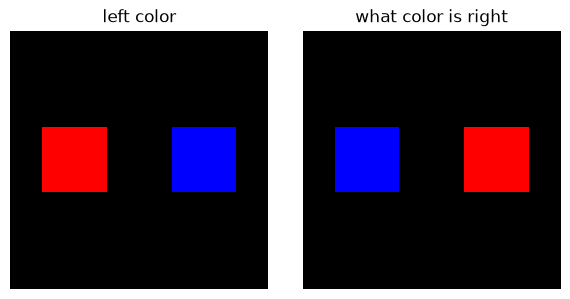

In [2]:
B, D, PATCH_SIZE = 2, 32, 8
images = torch.zeros(B, 3, 32, 32, device=device)
images[0, 0, 12:20, 4:12] = 1.0
images[0, 2, 12:20, 20:28] = 1.0
images[1, 2, 12:20, 4:12] = 1.0
images[1, 0, 12:20, 20:28] = 1.0
vocab = {"<pad>": 0, "what": 1, "color": 2, "is": 3, "left": 4, "right": 5}
sentences = ["left color", "what color is right"]
encoded = [[vocab[word] for word in sentence.split()] for sentence in sentences]
N_TEXT = max(map(len, encoded))
text_ids = torch.zeros(B, N_TEXT, dtype=torch.long, device=device)
for row, ids in enumerate(encoded):
    text_ids[row, :len(ids)] = torch.tensor(ids, device=device)

patch_embed = nn.Conv2d(3, D, PATCH_SIZE, stride=PATCH_SIZE).to(device)
text_embed = nn.Embedding(len(vocab), D, padding_idx=vocab["<pad>"]).to(device)
visual = patch_embed(images).flatten(2).transpose(1, 2)
N_VISUAL = visual.size(1)
visual_pos = nn.Parameter(torch.randn(1, N_VISUAL, D, device=device) * 0.02)
text_pos = nn.Parameter(torch.randn(1, N_TEXT, D, device=device) * 0.02)
modality = nn.Embedding(2, D).to(device)
nn.init.normal_(modality.weight, std=0.02)
visual = visual + visual_pos + modality.weight[0]
text = text_embed(text_ids) + text_pos + modality.weight[1]
text_padding = text_ids.eq(vocab["<pad>"])
combined = torch.cat([visual, text], dim=1)
key_padding = torch.cat([
    torch.zeros(B, N_VISUAL, dtype=torch.bool, device=device), text_padding
], dim=1)
print("image:", tuple(images.shape), "visual:", tuple(visual.shape))
print("text:", tuple(text.shape), "combined:", tuple(combined.shape))
print("text IDs:", text_ids.tolist())
fig, axes = plt.subplots(1, B, figsize=(6, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].permute(1, 2, 0).cpu())
    ax.set_title(sentences[i])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2. 手写 Multi-Head Attention

设 Query 长度为 $L_q$ ，Key/Value 长度为 $L_k$ ，Head 数为 $n_h=4$ ，每头维度为 $d_h=D/n_h$ ：

$$
A^{(h)}=\mathrm{softmax}\left(\frac{Q^{(h)}K^{(h)\top}}{\sqrt{d_h}}+M\right),
\qquad O^{(h)}=A^{(h)}V^{(h)}.
$$

Softmax 沿 Key 维进行。最终权重保留为 $[B,n_h,L_q,L_k]$ ，不对 Head 求平均；输出为 $[B,L_q,D]$ 。这里不使用 Attention Dropout，以便核对行和与代数关系。布尔 Mask 中 `True` 表示屏蔽。


In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, dim, heads=4):
        super().__init__()
        assert dim % heads == 0
        self.heads, self.head_dim = heads, dim // heads
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)

    def forward(self, query, key, value, key_padding_mask=None, attn_mask=None):
        batch, nq, dim = query.shape
        nk = key.size(1)
        assert key.shape == value.shape
        def split(x):
            return x.reshape(batch, -1, self.heads, self.head_dim).transpose(1, 2)
        q = split(self.q_proj(query))
        k = split(self.k_proj(key))
        v = split(self.v_proj(value))
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        blocked = torch.zeros(batch, 1, nq, nk, dtype=torch.bool, device=query.device)
        if attn_mask is not None:
            assert attn_mask.dtype == torch.bool and attn_mask.shape == (nq, nk)
            blocked = blocked | attn_mask[None, None]
        if key_padding_mask is not None:
            assert key_padding_mask.dtype == torch.bool
            assert key_padding_mask.shape == (batch, nk)
            blocked = blocked | key_padding_mask[:, None, None, :]
        if blocked.all(dim=-1).any():
            raise ValueError("Every query needs at least one visible key.")
        weights = scores.masked_fill(blocked, float("-inf")).softmax(dim=-1)
        context = (weights @ v).transpose(1, 2).contiguous().reshape(batch, nq, dim)
        return self.out_proj(context), weights


## 3. 两种融合方式读取哪些 Key？

联合 Self-Attention 使用 $[Z_v;Z_t]$ 作为 Q/K/V 来源；文本 Query 同时在视觉和有效文本 Key 中分配权重。Cross-Attention 使用文本作为 Query，视觉作为 Key/Value，输出位置仍对应文本。

为了只比较 Key 集合变化，下面共享同一个 Attention 模块及输入向量。实际训练两种架构时，参数和中间表示通常不同，不能直接套用这个受控比较的数值关系。


In [4]:
attention = MultiHeadAttention(D, heads=4).to(device).eval()
with torch.no_grad():
    joint_output, joint_weights = attention(combined, combined, combined, key_padding)
    cross_output, cross_weights = attention(text, visual, visual)
print("Joint:", tuple(joint_output.shape), tuple(joint_weights.shape))
print("Cross:", tuple(cross_output.shape), tuple(cross_weights.shape))
assert cross_weights.shape == (B, 4, N_TEXT, N_VISUAL)
assert joint_weights.masked_select(key_padding[:, None, None, :]).eq(0).all()
torch.testing.assert_close(cross_weights.sum(-1), torch.ones_like(cross_weights.sum(-1)))


Joint: (2, 20, 32) (2, 4, 20, 20)
Cross: (2, 4, 32) (2, 4, 4, 16)


## 4. 归一化范围为什么会改变权重？

取联合 Attention 中一个文本 Query 对视觉 Key 的子行，记视觉权重总和为 $m$ 。在本节共享 Q/K 投影、输入相同、视觉 Key 全部有效且无 Dropout 的条件下：

$$
A_{\mathrm{cross},j}=\frac{A_{\mathrm{joint},j}}{m},
\qquad
m=\sum_{j=1}^{N_v}A_{\mathrm{joint},j}.
$$

这个等式只涉及视觉权重。联合输出还包含文本 Value，因此它通常不等于 Cross-Attention 输出。把联合 Attention 的文本 Key 全部屏蔽后，文本 Query 的输出才应与这里的 Cross-Attention 一致。Padding Query 的计算结果不用于有效文本评价。


In [5]:
with torch.no_grad():
    joint_visual = joint_weights[:, :, N_VISUAL:, :N_VISUAL]
    visual_mass = joint_visual.sum(-1, keepdim=True)
    assert (visual_mass > 0).all()
    torch.testing.assert_close(joint_visual / visual_mass, cross_weights, atol=1e-6, rtol=1e-5)
    visual_only_keys = torch.cat([
        torch.zeros(B, N_VISUAL, dtype=torch.bool, device=device),
        torch.ones(B, N_TEXT, dtype=torch.bool, device=device)
    ], dim=1)
    restricted_output, restricted_weights = attention(
        combined, combined, combined, key_padding_mask=visual_only_keys)
    torch.testing.assert_close(restricted_output[:, N_VISUAL:], cross_output, atol=1e-6, rtol=1e-5)
print("Restricted joint output vs cross output: max error",
      (restricted_output[:, N_VISUAL:] - cross_output).abs().max().item())
last_text = int((~text_padding[0]).sum().item()) - 1
print("Joint visual-key mass per head:", visual_mass[0, :, last_text, 0].tolist())
print("Cross visual-key mass per head:", cross_weights[0, :, last_text].sum(-1).tolist())


Restricted joint output vs cross output: max error 2.9802322387695312e-08
Joint visual-key mass per head: [0.9110443592071533, 0.879431962966919, 0.8868297338485718, 0.8982886075973511]
Cross visual-key mass per head: [1.0, 1.0, 1.0, 1.0]


## 5. 每个 Head 独立显示

选第一张图的最后一个有效文本 Query，将视觉权重恢复为 4×4 Patch 网格。每张图使用独立 colorbar 和自己的颜色范围，跨图比较绝对值应读取刻度。由于第 4 节的归一化关系，同一 Head 的两幅图空间形状相同；这不代表两种融合结构等价，也不表明未训练模型学到了语义定位。


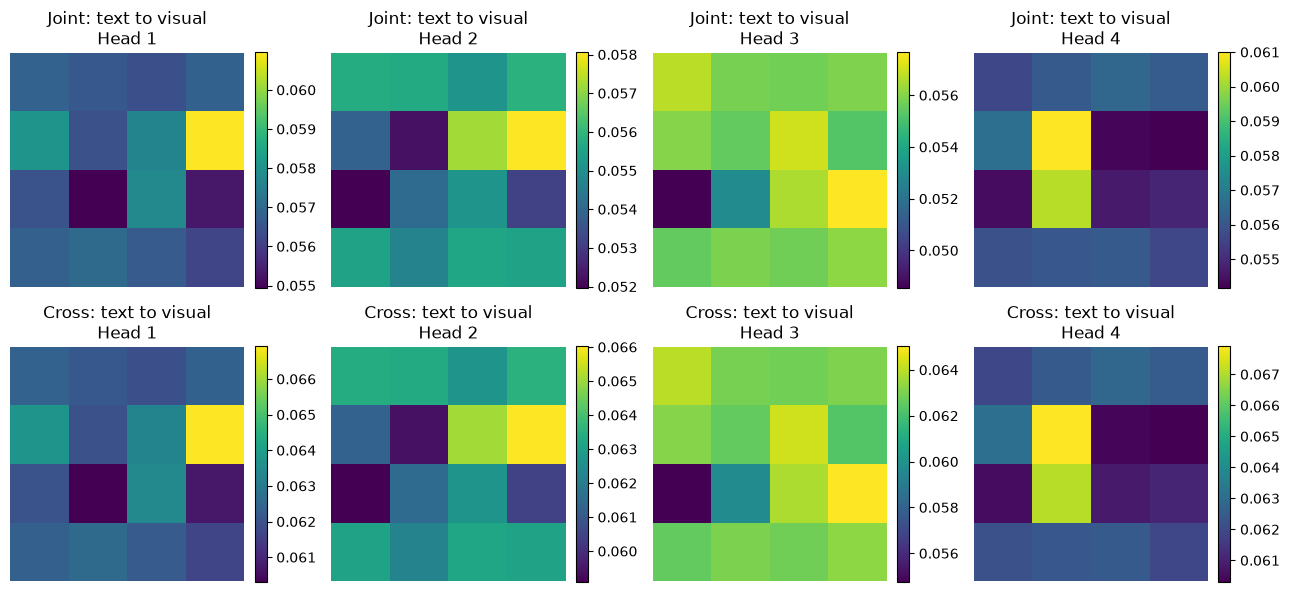

In [6]:
grid_size = 32 // PATCH_SIZE
maps = [
    joint_visual[0, :, last_text].reshape(4, grid_size, grid_size).cpu(),
    cross_weights[0, :, last_text].reshape(4, grid_size, grid_size).cpu(),
]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for row, (name, values) in enumerate(zip(["Joint: text to visual", "Cross: text to visual"], maps)):
    for head in range(4):
        data = values[head].numpy()
        im = axes[row, head].imshow(data, cmap="viridis", vmin=data.min(), vmax=data.max())
        axes[row, head].set_title(f"{name}\nHead {head + 1}")
        axes[row, head].axis("off")
        fig.colorbar(im, ax=axes[row, head], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 6. Attention 输出如何进入完整的文本 Block？

Cross-Attention 输出是按文本 Query 从视觉 Value 读取的特征，不会自动包含文本残差和 FFN。下面给出 Post-LN 融合子块：

$$
U=\mathrm{LN}(Z_t+\mathrm{CrossAttn}(Z_t,Z_v,Z_v)),
\qquad
Y=\mathrm{LN}(U+\mathrm{FFN}(U)).
$$

这里只展示一次前向计算，没有训练此 Block。输入扰动可以检查计算依赖，不能替代任务评价。


In [7]:
norm1, norm2 = nn.LayerNorm(D).to(device), nn.LayerNorm(D).to(device)
ffn = nn.Sequential(nn.Linear(D, 4 * D), nn.GELU(), nn.Linear(4 * D, D)).to(device)
fused = norm1(text + cross_output)
fused = norm2(fused + ffn(fused))
with torch.no_grad():
    changed_visual = visual.clone()
    changed_visual[:, 0] += torch.randn(D, device=device)
    changed_readout, _ = attention(text, changed_visual, changed_visual)
print("Fused text features:", tuple(fused.shape))
print("Visual perturbation changes valid text outputs:",
      (changed_readout[~text_padding] - cross_output[~text_padding]).norm().item())


Fused text features: (2, 4, 32)
Visual perturbation changes valid text outputs: 0.2694033086299896


## 7. 回顾

联合 Self-Attention 与 Cross-Attention 是两种信息组织方式，不存在由本节直接证明的普遍优劣。下一节选择联合 Self-Attention，训练一个同时需要图像与问题的任务；它不是两种架构的训练性能对照实验。

[项目首页](../README.md) · [上一节](02_Visual_Language_Projection.ipynb) · [下一节：完整训练实验](04_Mini_Multimodal_Transformer.ipynb)
